# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hajergafsi/flyrank-ml-internship-starter/blob/main/work/notebooks/w07_action_playbook.ipynb)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

In [4]:
from pathlib import Path
import subprocess
import os

REPO_URL = "https://github.com/hajergafsi/flyrank-ml-internship-starter.git"
CLONE_DIR = Path("/content/flyrank-ml-internship-starter")

if not CLONE_DIR.exists():
    subprocess.run(
        ["git", "clone", REPO_URL, str(CLONE_DIR)],
        check=True
    )
else:
    print("Repository already exists:", CLONE_DIR)

# Search for the starter dataset.
matches = list(
    Path("/content").rglob("content_refresh_anonymized.csv")
)

if matches:
    print("Found dataset:")
    for match in matches:
        print(match)
else:
    print("Dataset was not found in the cloned repository.")
    print("Repository contents:")
    print(list(CLONE_DIR.iterdir())[:20])

Found dataset:
/content/flyrank-ml-internship-starter/data/raw/content_refresh_anonymized.csv


In [5]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the repository and starter dataset anywhere under /content.
dataset_matches = list(
    Path("/content").rglob("content_refresh_anonymized.csv")
)

if not dataset_matches:
    raise FileNotFoundError(
        "The repository was cloned, but "
        "content_refresh_anonymized.csv was not found. "
        "Check the repository contents or upload the dataset manually."
    )

starter_path = dataset_matches[0]
ROOT = starter_path.parent.parent.parent

print("Dataset:", starter_path)
print("Repository root:", ROOT)

OUTPUT_DIR = ROOT / "work" / "outputs"
FIGURE_DIR = ROOT / "work" / "figures"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

baseline_path = OUTPUT_DIR / "baseline_action_score.csv"

if baseline_path.exists():
    queue = pd.read_csv(baseline_path)
    source_used = "work/outputs/baseline_action_score.csv"
else:
    queue = pd.read_csv(starter_path)
    source_used = "data/raw/content_refresh_anonymized.csv"

    queue = queue.rename(
        columns={
            "content_id": "content_hash_id",
            "client_id": "client_hash_id",
        }
    )

    queue["avg_impressions"] = pd.to_numeric(
        queue["impressions_90d"],
        errors="coerce",
    ).fillna(0)

    queue["avg_position"] = pd.to_numeric(
        queue["avg_position"],
        errors="coerce",
    )

    # In this dataset, avg_position == 0 means no position data.
    queue.loc[queue["avg_position"] == 0, "avg_position"] = np.nan

    # Starter CSV CTR values are percentages:
    # 0.76 means 0.76%, not 76%.
    queue["ctr_percent"] = pd.to_numeric(
        queue["ctr"],
        errors="coerce",
    ).fillna(0)

    volume_signal = np.log1p(queue["avg_impressions"])
    volume_score = (
        (volume_signal - volume_signal.min())
        / (
            volume_signal.max() - volume_signal.min()
            if volume_signal.max() != volume_signal.min()
            else 1
        )
    )

    position_signal = -queue["avg_position"].fillna(
        queue["avg_position"].max()
    )
    position_score = (
        (position_signal - position_signal.min())
        / (
            position_signal.max() - position_signal.min()
            if position_signal.max() != position_signal.min()
            else 1
        )
    )

    low_ctr_signal = -queue["ctr_percent"]
    low_ctr_score = (
        (low_ctr_signal - low_ctr_signal.min())
        / (
            low_ctr_signal.max() - low_ctr_signal.min()
            if low_ctr_signal.max() != low_ctr_signal.min()
            else 1
        )
    )

    queue["priority_score"] = (
        0.40 * volume_score
        + 0.35 * position_score
        + 0.25 * low_ctr_score
    )

if "days_since_last_update" not in queue.columns:
    queue["days_since_last_update"] = np.nan

if "trend_direction" not in queue.columns:
    queue["trend_direction"] = "not_available"

queue["days_since_last_update"] = pd.to_numeric(
    queue["days_since_last_update"],
    errors="coerce",
)

enough_volume = queue["avg_impressions"] >= 100
has_position = (
    queue["avg_position"].notna()
    & (queue["avg_position"] > 0)
)

low_ctr_visible = (
    enough_volume
    & has_position
    & (queue["avg_position"] <= 20)
    & (queue["ctr_percent"] < 1.0)
)

stale_refresh_candidate = (
    enough_volume
    & queue["days_since_last_update"].ge(365)
)

declining_high_value = (
    enough_volume
    & queue["trend_direction"].astype(str).str.lower().eq("down")
)

insufficient_data = (
    (queue["avg_impressions"] < 100)
    | queue["avg_position"].isna()
)

queue["reason_code"] = np.select(
    [
        insufficient_data,
        low_ctr_visible,
        declining_high_value,
        stale_refresh_candidate,
    ],
    [
        "insufficient_data",
        "low_ctr_visible_page",
        "declining_high_value_review",
        "stale_refresh_candidate",
    ],
    default="monitor_no_priority_flag",
)

queue["action"] = np.select(
    [
        queue["reason_code"].eq("insufficient_data"),
        queue["reason_code"].eq("low_ctr_visible_page"),
        queue["reason_code"].eq("declining_high_value_review"),
        queue["reason_code"].eq("stale_refresh_candidate"),
    ],
    [
        "do_not_prioritize_without_more_data",
        "review_title_and_meta",
        "review_trend_and_business_context",
        "review_refresh_opportunity",
    ],
    default="monitor",
)

queue.loc[
    queue["reason_code"].eq("insufficient_data"),
    "priority_score",
] -= 0.20

queue = queue.sort_values(
    ["priority_score", "avg_impressions"],
    ascending=[False, False],
).reset_index(drop=True)

queue["rank"] = np.arange(1, len(queue) + 1)

print("Source used:", source_used)
print("Rows:", f"{len(queue):,}")

display(
    queue[
        [
            "rank",
            "content_hash_id",
            "client_hash_id",
            "priority_score",
            "reason_code",
            "action",
            "avg_impressions",
            "avg_position",
            "ctr_percent",
        ]
    ].head(20)
)

Dataset: /content/flyrank-ml-internship-starter/data/raw/content_refresh_anonymized.csv
Repository root: /content/flyrank-ml-internship-starter
Source used: data/raw/content_refresh_anonymized.csv
Rows: 30,000


,rank,content_hash_id,client_hash_id,priority_score,reason_code,action,avg_impressions,avg_position,ctr_percent
0,1,content_8c19996aa890,client_4e07408562,0.995666,low_ctr_visible_page,review_title_and_meta,509252,2.5,0.15
1,2,content_5fe46e04994d,client_4e07408562,0.993790,low_ctr_visible_page,review_title_and_meta,517715,4.2,0.14
2,3,content_4c36c775b818,client_4e07408562,0.992253,low_ctr_visible_page,review_title_and_meta,463103,2.3,0.41
3,4,content_aaef01a50def,client_19581e27de,0.991763,low_ctr_visible_page,review_title_and_meta,517109,5.4,0.25
4,5,content_1a9e894be2e2,client_19581e27de,0.986845,low_ctr_visible_page,review_title_and_meta,416180,4.0,0.23
5,6,content_44e481c8f55b,client_19581e27de,0.980336,low_ctr_visible_page,review_title_and_meta,312694,1.4,0.65
6,7,content_2c2606c5d176,client_19581e27de,0.980012,low_ctr_visible_page,review_title_and_meta,347399,4.2,0.53
7,8,content_db5989a78dd3,client_4e07408562,0.978885,low_ctr_visible_page,review_title_and_meta,345111,5.4,0.21
8,9,content_9532f197bbc8,client_4e07408562,0.978567,low_ctr_visible_page,review_title_and_meta,309192,2.0,0.87
9,10,content_8451fc6f034d,client_d029fa3a95,0.976143,low_ctr_visible_page,review_title_and_meta,272144,2.3,0.03


## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

In [6]:
intended_use = pd.DataFrame(
    [
        {
            "topic": "Who uses it",
            "statement": (
                "Content strategists, SEO analysts, and editorial reviewers use this queue "
                "to decide which pages to inspect first."
            ),
        },
        {
            "topic": "Intended decision",
            "statement": (
                "The queue supports review prioritization. It does not automatically decide "
                "what content should be changed."
            ),
        },
        {
            "topic": "Meaning of the score",
            "statement": (
                "The priority score is a transparent ranking heuristic based mainly on "
                "impressions, position, and CTR. It is not a probability or guaranteed outcome."
            ),
        },
        {
            "topic": "Validation scope",
            "statement": (
                "The Random Forest evidence came from a March 2026 warehouse slice using "
                "features before March 15, 2026 and a grouped-by-client validation split."
            ),
        },
        {
            "topic": "Measured validation result",
            "statement": (
                "Under the grouped-by-client split, the model reported ROC-AUC 0.7904, "
                "average precision 0.4421, and precision@50 of 0.38 with a test base rate of 0.2323."
            ),
        },
        {
            "topic": "Label limitation",
            "statement": (
                "The decline label is a short-window impression-decline proxy. It is not "
                "a complete measure of content quality, revenue, or business value."
            ),
        },
        {
            "topic": "Refresh limitation",
            "statement": (
                "Older pages are review candidates because freshness may be a directional "
                "signal. The available evidence does not prove that refreshing a page causes lift."
            ),
        },
        {
            "topic": "Data limitation",
            "statement": (
                "Sparse impressions, missing position data, seasonality, technical problems, "
                "tracking changes, and client differences can make a recommendation unreliable."
            ),
        },
        {
            "topic": "Leakage limitation",
            "statement": (
                "Future-window values and label-derived fields must not be used as features. "
                "The leakage audit showed that doing so can inflate ROC-AUC from 0.7904 to 0.9474."
            ),
        },
    ]
)

display(intended_use)

,topic,statement
0,Who uses it,"Content strategists, SEO analysts, and editori..."
1,Intended decision,The queue supports review prioritization. It d...
2,Meaning of the score,The priority score is a transparent ranking he...
3,Validation scope,The Random Forest evidence came from a March 2...
4,Measured validation result,"Under the grouped-by-client split, the model r..."
5,Label limitation,The decline label is a short-window impression...
6,Refresh limitation,Older pages are review candidates because fres...
7,Data limitation,"Sparse impressions, missing position data, sea..."
8,Leakage limitation,Future-window values and label-derived fields ...


## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

In [7]:
human_review_rules = pd.DataFrame(
    [
        {
            "check": "Search intent",
            "rule": "Review the queries, SERP context, competitors, and whether the page matches the expected search intent.",
        },
        {
            "check": "Business value",
            "rule": "Confirm that the page matters to the business before spending editorial or engineering time.",
        },
        {
            "check": "Accuracy",
            "rule": "Verify facts, dates, prices, regulations, citations, and examples before changing content.",
        },
        {
            "check": "Cannibalization",
            "rule": "Check related pages before editing, consolidating, redirecting, or changing internal links.",
        },
        {
            "check": "Technical causes",
            "rule": "Check indexing, canonical tags, redirects, robots rules, rendering, speed, and analytics coverage.",
        },
        {
            "check": "Data sufficiency",
            "rule": "Do not act on sparse impressions, missing position data, or unexplained measurement changes.",
        },
        {
            "check": "Brand and compliance",
            "rule": "Escalate legal, medical, financial, safety, privacy, and reputation-sensitive topics.",
        },
    ]
)

no_go_list = pd.DataFrame(
    [
        {
            "no_go": "Automatically publish content edits",
            "reason": "The score cannot verify accuracy, intent, tone, compliance, or brand fit.",
        },
        {
            "no_go": "Automatically change factual claims",
            "reason": "A human or subject-matter expert must verify the facts.",
        },
        {
            "no_go": "Automatically delete, redirect, or consolidate pages",
            "reason": "These actions require technical, business, and cannibalization review.",
        },
        {
            "no_go": "Automate high-stakes content decisions",
            "reason": "High-stakes topics require specialist review.",
        },
        {
            "no_go": "Act on insufficient-data rows",
            "reason": "Sparse or missing data can create unstable recommendations.",
        },
        {
            "no_go": "Treat refresh as guaranteed growth",
            "reason": "The available evidence is observational and does not establish causality.",
        },
        {
            "no_go": "Use target-window fields as features",
            "reason": "That would create leakage and invalidate the evaluation.",
        },
    ]
)

print("Human review rules")
display(human_review_rules)

print("No-go list")
display(no_go_list)

Human review rules


,check,rule
0,Search intent,"Review the queries, SERP context, competitors,..."
1,Business value,Confirm that the page matters to the business ...
2,Accuracy,"Verify facts, dates, prices, regulations, cita..."
3,Cannibalization,"Check related pages before editing, consolidat..."
4,Technical causes,"Check indexing, canonical tags, redirects, rob..."
5,Data sufficiency,"Do not act on sparse impressions, missing posi..."
6,Brand and compliance,"Escalate legal, medical, financial, safety, pr..."


No-go list


,no_go,reason
0,Automatically publish content edits,"The score cannot verify accuracy, intent, tone..."
1,Automatically change factual claims,A human or subject-matter expert must verify t...
2,"Automatically delete, redirect, or consolidate...","These actions require technical, business, and..."
3,Automate high-stakes content decisions,High-stakes topics require specialist review.
4,Act on insufficient-data rows,Sparse or missing data can create unstable rec...
5,Treat refresh as guaranteed growth,The available evidence is observational and do...
6,Use target-window fields as features,That would create leakage and invalidate the e...


## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

In [8]:
monitoring_plan = pd.DataFrame(
    [
        {
            "metric": "Queue size",
            "cadence": "Every refresh",
            "trigger": "Investigate if total or actionable rows change by more than 30%.",
            "response": "Check filters, source coverage, date windows, and ingestion changes.",
        },
        {
            "metric": "Reason-code mix",
            "cadence": "Every refresh",
            "trigger": "Investigate if a reason-code share changes by more than 20 percentage points.",
            "response": "Review threshold behavior, missingness, and population changes.",
        },
        {
            "metric": "Feature drift",
            "cadence": "Monthly",
            "trigger": "Investigate major changes in impressions, CTR, position, age, or update recency.",
            "response": "Re-check whether score weights and thresholds remain useful.",
        },
        {
            "metric": "Missingness",
            "cadence": "Every refresh",
            "trigger": "Pause recommendations if key fields become materially less complete.",
            "response": "Repair measurement before changing the scoring logic.",
        },
        {
            "metric": "Grouped validation",
            "cadence": "Monthly or after pipeline changes",
            "trigger": "Investigate if average precision or precision@K falls by more than 20% from the validation receipt.",
            "response": "Re-run grouped-by-client validation and inspect errors.",
        },
        {
            "metric": "Human review yield",
            "cadence": "Each review batch",
            "trigger": "Investigate if fewer than half of reviewed rows are considered actionable.",
            "response": "Review thresholds, reason codes, and reviewer feedback.",
        },
        {
            "metric": "Human override rate",
            "cadence": "Each review batch",
            "trigger": "Investigate if reviewers override more than 40% of top-ranked recommendations.",
            "response": "Check whether the queue overweights volume or misses context.",
        },
        {
            "metric": "Feature/label alignment",
            "cadence": "Every retrain",
            "trigger": "Any change to feature or target dates triggers a leakage review.",
            "response": "Confirm all features precede the target window.",
        },
    ]
)

display(monitoring_plan)

print(
    "Retrain only after investigating population drift, data-quality changes, "
    "feature/label changes, or sustained loss of grouped holdout performance."
)

,metric,cadence,trigger,response
0,Queue size,Every refresh,Investigate if total or actionable rows change...,"Check filters, source coverage, date windows, ..."
1,Reason-code mix,Every refresh,Investigate if a reason-code share changes by ...,"Review threshold behavior, missingness, and po..."
2,Feature drift,Monthly,"Investigate major changes in impressions, CTR,...",Re-check whether score weights and thresholds ...
3,Missingness,Every refresh,Pause recommendations if key fields become mat...,Repair measurement before changing the scoring...
4,Grouped validation,Monthly or after pipeline changes,Investigate if average precision or precision@...,Re-run grouped-by-client validation and inspec...
5,Human review yield,Each review batch,Investigate if fewer than half of reviewed row...,"Review thresholds, reason codes, and reviewer ..."
6,Human override rate,Each review batch,Investigate if reviewers override more than 40...,Check whether the queue overweights volume or ...
7,Feature/label alignment,Every retrain,Any change to feature or target dates triggers...,Confirm all features precede the target window.


Retrain only after investigating population drift, data-quality changes, feature/label changes, or sustained loss of grouped holdout performance.


## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

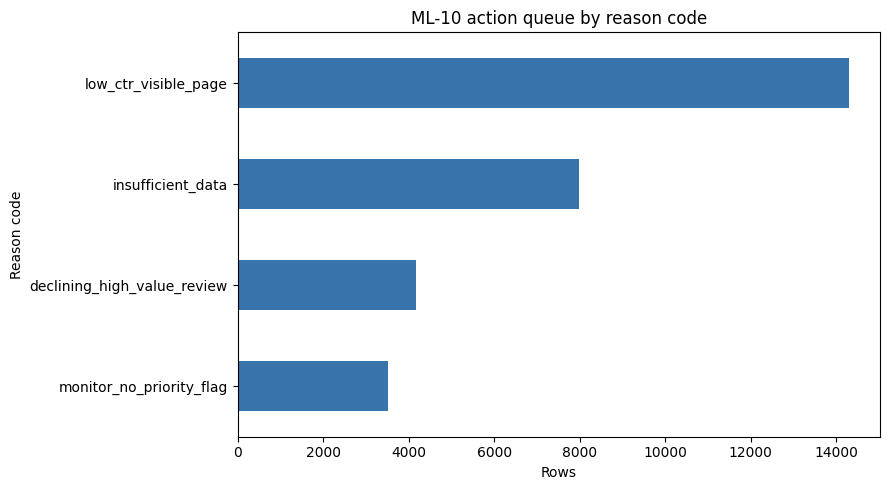

Wrote: /content/flyrank-ml-internship-starter/work/outputs/w07_action_playbook_queue.csv
Wrote: /content/flyrank-ml-internship-starter/work/figures/w07_reason_code_mix.png
Wrote: /content/flyrank-ml-internship-starter/work/outputs/w07_action_playbook_metrics.json


In [9]:
# Export a compact ranked queue.
queue_columns = [
    "rank",
    "content_hash_id",
    "client_hash_id",
    "priority_score",
    "reason_code",
    "action",
    "avg_impressions",
    "avg_position",
    "ctr_percent",
    "days_since_last_update",
]

queue_export = queue[
    [column for column in queue_columns if column in queue.columns]
].copy()

queue_path = OUTPUT_DIR / "w07_action_playbook_queue.csv"
queue_export.to_csv(queue_path, index=False)

# Export reason-code figure.
reason_counts = queue["reason_code"].value_counts().sort_values()

plt.figure(figsize=(9, 5))
reason_counts.plot(kind="barh", color="#3973ac")
plt.title("ML-10 action queue by reason code")
plt.xlabel("Rows")
plt.ylabel("Reason code")
plt.tight_layout()

figure_path = FIGURE_DIR / "w07_reason_code_mix.png"
plt.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close()

# Export committed metrics receipt.
metrics = {
    "assignment": "ML-10 Content Action Playbook",
    "source": source_used,
    "queue_rows": int(len(queue)),
    "actionable_rows": int(
        (~queue["reason_code"].isin(
            ["monitor_no_priority_flag", "insufficient_data"]
        )).sum()
    ),
    "reason_code_counts": {
        str(k): int(v)
        for k, v in queue["reason_code"].value_counts().items()
    },
    "validation": {
        "split": "grouped-by-client",
        "test_base_rate": 0.2323,
        "roc_auc": 0.7904,
        "average_precision": 0.4421,
        "precision_at_50": 0.38,
    },
    "interpretation": [
        "The queue is decision-support for human review prioritization.",
        "The score is not a probability or causal estimate.",
        "Refresh candidates are directional hypotheses for review.",
        "Publishing, factual changes, deletion, and redirects remain human decisions.",
    ],
}

metrics_path = OUTPUT_DIR / "w07_action_playbook_metrics.json"
with metrics_path.open("w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=2)

print("Wrote:", queue_path)
print("Wrote:", figure_path)
print("Wrote:", metrics_path)

## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.